### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 7
### Due: Wednesday, Nov. 18 at 11.59pm CT
---

## Problem 1

This is a regression problem. Many of the parts require minor variations of code to switch to new techniques, but otherwise using a similar workflow. 

Note of warning: the data I have provided have associated uncertainties, `yerr`. `sklearn` and `astroML` have different formats for using uncertainties; in `sklearn` fitting you can provide `sample_weight=1/yerr**2`, while in `astroML` fitting you can directly provide `y_error=yerr`.

1. Read in `hw7_data_1.npy`. The dataset should consist of $500$ samples. The first two columns are the two data features, `X`. The third column is the target labels, `y`, and the final column are the heteroscedastic uncertainties on the labels, `yerr`. Make a 2-panel scatter plot of the labels versus each feature.


2. Use multivariate linear regression on this data with its uncertainties (`astroML` rather than plain `sklearn` is the better option here). Print the best-fit intercept and slopes for the features. Make a prediction `Xgrid` over $50$ values from the min to the max value of each feature, and plot the best-fit model on a duplicate of the $2$-panel plot from (1); does this look like a good description of the data?


3. Make a new two-dimensional prediction meshgrid `Xgrid` over the $2$-D feature space, use your best-fit model to predict the labels, and make a $3$-D interactive plot showing the data and your best-fit over the entire space. You may find the following code useful.

In [1]:
# install the relevant interactive plot packages
# only do this once
!pip install ipympl ipywidgets

In [2]:
# Makes the plot interactive. 
# You can pan the image.

### always do this line at the start 
### of an interactive plotting cell
%matplotlib widget 
fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(___, ___, y, color='k', 
        zorder=15, linestyle='none', 
        marker='o', alpha=0.5)
ax.scatter(___.flatten(), ___.flatten(), ___, 
           facecolor=(0,0,0,0), s=20, 
           edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

NameError: name 'plt' is not defined

In [3]:
### Always do this line at the start
### of a static plotting cell
%matplotlib inline

4. Sticking with a linear model, now attempt a `GridSearchCV` procedure on the data to find the best `Ridge` regression hyper-parameters. Use the following `param_grid`:
```
ridge_params = {'alpha': [0.05,0.1,0.2,0.5,1.0], 'solver': ['svd', 'lsqr']}
```
What are the `best_params_` and the `best_score_` from this? Fit the data with the best options, and visualize interactively. Try `RidgeCV` also; what cross-validated `alpha_` does it return, and does this agree with `GridSeachCV`? *(Hint: remember to revert to inline matplotlib when you're done each time you make an interactive plot.)*


5. Now model the data using Gaussian process regression and the default kernel. Check what the fit looks like with and with and without uncertainties accounted for. *(Hint: GPR in `sklearn` takes an `alpha` parameter equal to `(yerr/y)**2`.)*


6. Let's look finally at polynomial fitting. Fit a $4$th degree polynomial to the data. Print the best-fit regression coefficients, predict on the 2D meshgrid, and visualize interactively as before. How does this look compared to the linear model and GPR models?


7. Sticking with polynomial fitting, let's find the optimal hyper-parameters through cross-validation. 
- Using `sklearn.model_selection.train_test_split`, first do a train-test split with a `test_size` of $20\%$. Then split out $20\%$ of the training set itself as a cross-validation set (leaving a somewhat smaller set to use for training). Note that you'll need to simultaneously split out `yerr` as well by just providing this as another array to `train_test_split`.
- Compute the training and cross-validation rms errors (and from those, the BIC values) as a function of polynomial degree from $1$ to $10$ inclusive. Plot the rms errors and BIC values as a function of the polynomial degree. 
- Choose the optimal polynomial degree, and train on all training data from the first `train_test_split` operation. Predict the labels of the held-out test set, and finally compute the testing rms error.

In [1]:
#part 1
#imports
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#load data
data1 = np.load('hw_data/hw7_data_1.npy')
X = data1[:, :2]
y = data1[:, 2]
yerr = data1[:, 3]

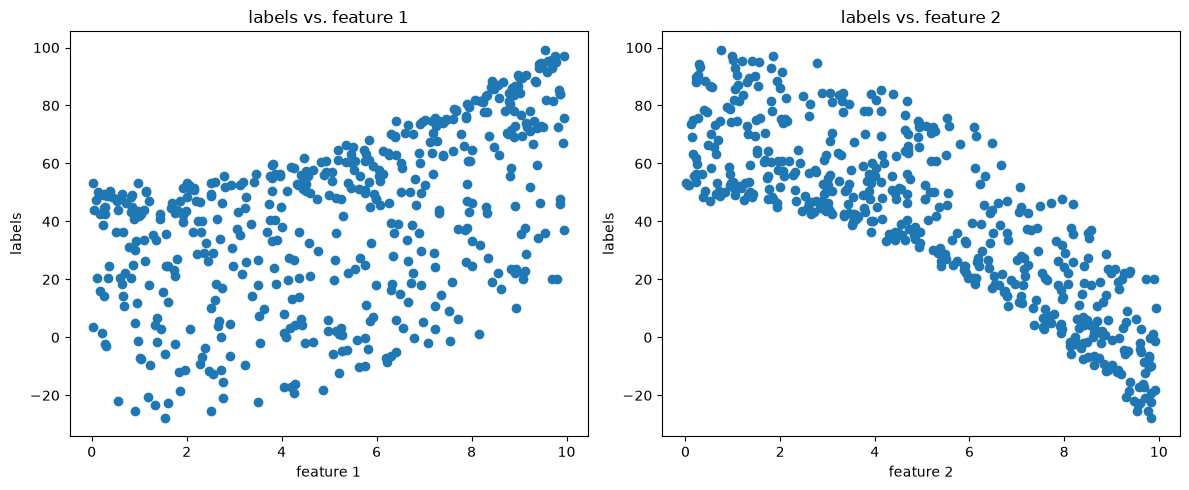

In [3]:
#plot
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

#feature 1
ax[0].scatter(X[:, 0], y)
ax[0].set_xlabel('feature 1')
ax[0].set_ylabel('labels')
ax[0].set_title('labels vs. feature 1')

#feature 2
ax[1].scatter(X[:, 1], y)
ax[1].set_xlabel('feature 2')
ax[1].set_ylabel('labels')
ax[1].set_title('labels vs. feature 2')

plt.tight_layout()
plt.show()

In [4]:
#part 2
#from lecture 17
from astroML.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y, yerr)

print('intercept:', model.clf_.intercept_)
print('slope for feature 1:', model.clf_.coef_[0])
print('slope for feature 2:', model.clf_.coef_[1])

intercept: 0.0
slope for feature 1: 57.1010232329955
slope for feature 2: 4.948730161178383


C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\astroML\linear_model\linear_regression_errors.py:10: UserWarning: LinearRegressionwithErrors requires PyMC3 to be installed
  warnings.warn('LinearRegressionwithErrors requires PyMC3 to be installed')


In [5]:
#prediction Xgrid
Xgrid1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 50)
Xgrid2 = np.linspace(X[:, 1].min(), X[:, 1].max(), 50)
Xgrid = np.column_stack([Xgrid1, Xgrid2])
y_pred = model.predict(Xgrid)

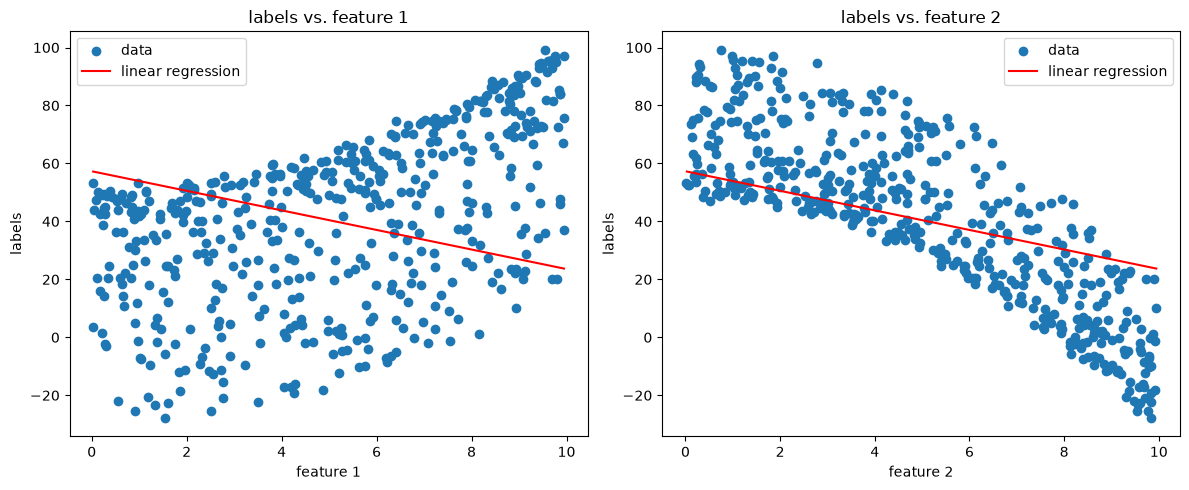

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

#feature 1
ax[0].scatter(X[:, 0], y, label='data')
ax[0].plot(Xgrid1, y_pred, color='red', label='linear regression')
ax[0].set_xlabel('feature 1')
ax[0].set_ylabel('labels')
ax[0].set_title('labels vs. feature 1')
ax[0].legend()

#feature 2
ax[1].scatter(X[:, 1], y, label='data')
ax[1].plot(Xgrid1, y_pred, color='red', label='linear regression')
ax[1].set_xlabel('feature 2')
ax[1].set_ylabel('labels')
ax[1].set_title('labels vs. feature 2')
ax[1].legend()

plt.tight_layout()
plt.show()

the linear regression fits well enough for feature 2, but does not describe feature 1 very well

In [7]:
#part 3
#2D meshgrid
X1, X2 = np.meshgrid(Xgrid1, Xgrid2)
Xgrid_new = np.column_stack([X1.ravel(), X2.ravel()])
y_pred1 = model.predict(Xgrid_new)
y_pred_new = y_pred1.reshape(X1.shape)

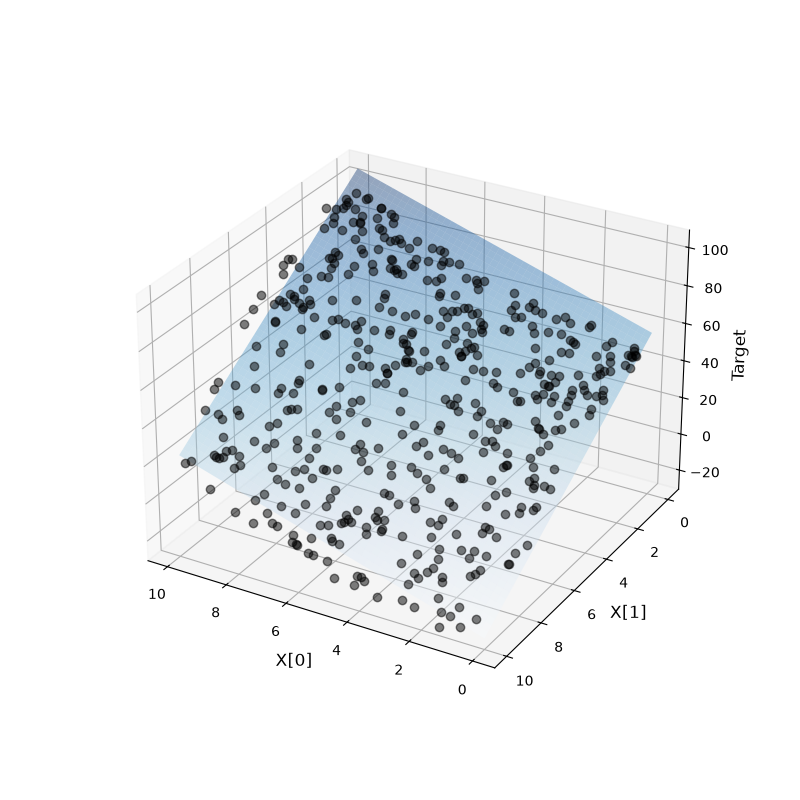

In [9]:
#plot
%matplotlib widget

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

#data
ax.plot(X[:, 0], X[:, 1], y, color='k',
        zorder=15, linestyle='none',
        marker='o', alpha=0.5)

#predicted surface
ax.plot_surface(X1, X2, y_pred_new, alpha=0.4, cmap='Blues')

ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

plt.show()

In [10]:
#part 4
#from lecture 18
#imports
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

In [12]:
#given param_grid
ridge_params = {'alpha': [0.05, 0.1, 0.2, 0.5, 1.0], 'solver': ['svd', 'lsqr']}

In [13]:
model = Ridge()
grid = GridSearchCV(model, ridge_params, cv=5)

In [14]:
grid.fit(X, y, sample_weight=1/yerr**2)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': [0.05, 0.1, ...], 'solver': ['svd', 'lsqr']}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, wit

In [16]:
print("best params:", grid.best_params_)
print("best scores:", grid.best_score_)

best params: {'alpha': 1.0, 'solver': 'svd'}
best scores: 0.9210232503685034


In [17]:
model = grid.best_estimator_

In [18]:
#create meshgrid
Xgrid2 = np.column_stack([X1.flatten(), X2.flatten()])

In [19]:
#predict 
y_pred2 = model.predict(Xgrid2)
y_pred2 = y_pred2.reshape(X1.shape)

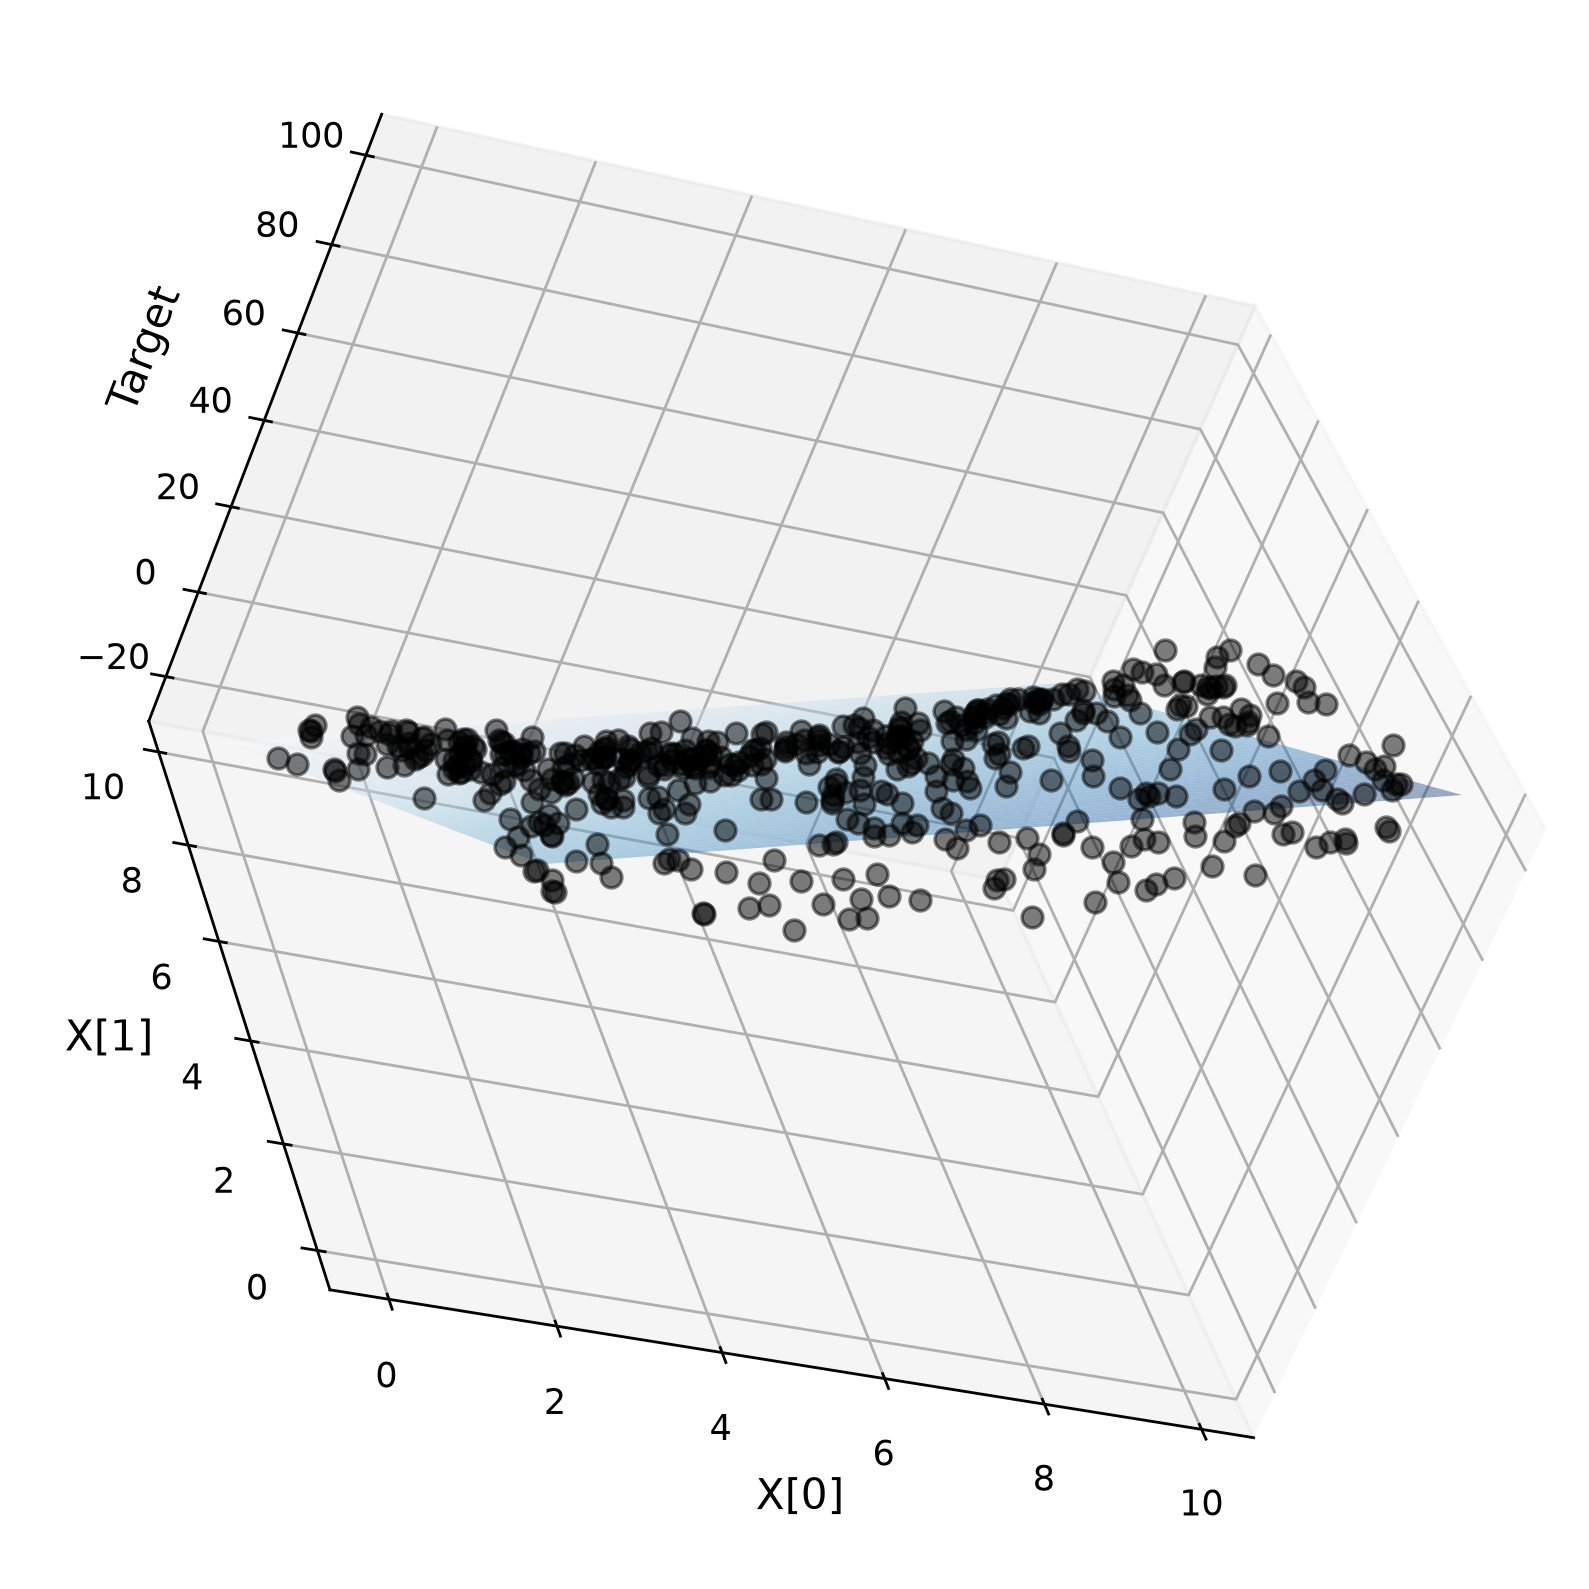

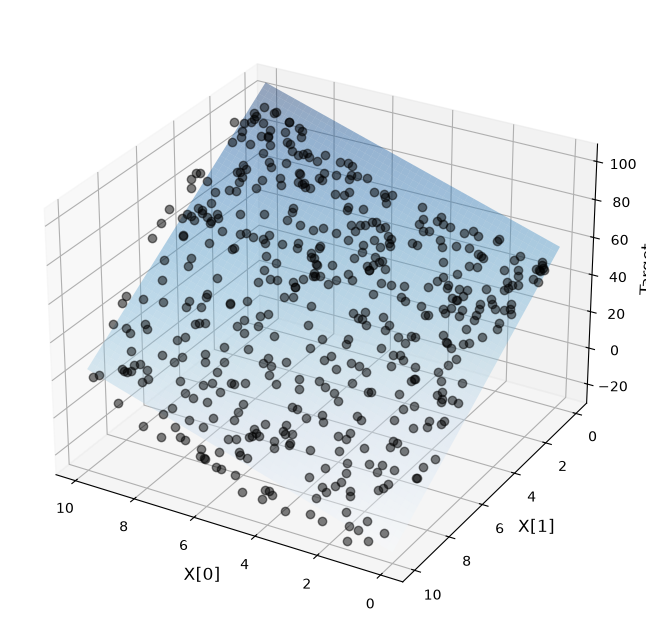

In [20]:
#plot
%matplotlib inline

fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:,0], X[:,1], y, color='k',
        zorder=15, linestyle='none',
        marker='o', alpha=0.5)

ax.plot_surface(X1, X2, y_pred2, alpha=0.4, cmap='Blues')

ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)
plt.show()

In [21]:
#ridge cv
from sklearn.linear_model import RidgeCV
model_cv = RidgeCV(alphas=[0.05, 0.1, 0.2, 0.5, 1.0], cv=5)
model_cv.fit(X, y, sample_weight=1/yerr**2)
print("best alpha:", model_cv.alpha_)

best alpha: 1.0


In [22]:
#part 5
#import
from sklearn.gaussian_process import GaussianProcessRegressor

In [23]:
gp = GaussianProcessRegressor()
gp.fit(X, y)

C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.",None
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-10
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",0
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False
,"copy_X_train copy_X_train: bool, default=TrueIf True, a persistent copy of the training data is stored in theobject. Otherwise, just a reference to the training data is stored,which might cause predictions to change if the data is modifiedexternally.",True
,"n_targets n_targets: int, default=NoneThe number of dimensions of the target values. Used to decide the numberof outputs when sampling from the prior distributions (i.e. calling:meth:`sample_y` before :meth:`fit`). This parameter is ignored once:meth:`fit` has been called... versionadded:: 1.3",None
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation used to initialize the centers.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None
Name,Type,Value
"L_ 

In [26]:
#without uncertainties
y_pred3, dy_pred3 = gp.predict(Xgrid2, return_std=True)
y_pred3 = y_pred3.reshape(X1.shape)
dy_pred3 = dy_pred3.reshape(X1.shape)

In [27]:
#with uncertainties
gp_err = GaussianProcessRegressor(alpha=(yerr/y)**2)
gp_err.fit(X, y)

y_pred_err, dy_pred_err = gp_err.predict(Xgrid2, return_std=True)
y_pred_err = y_pred_err.reshape(X1.shape)
dy_pred_err = dy_pred_err.reshape(X1.shape)

C:\Users\sydne\New folder\envs\astr5300\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [28]:
#grid
y_pred4, dy_pred4 = gp.predict(Xgrid_new, return_std=True)
y_pred4 = y_pred4.reshape(X1.shape)
dy_pred4 = dy_pred4.reshape(X1.shape)

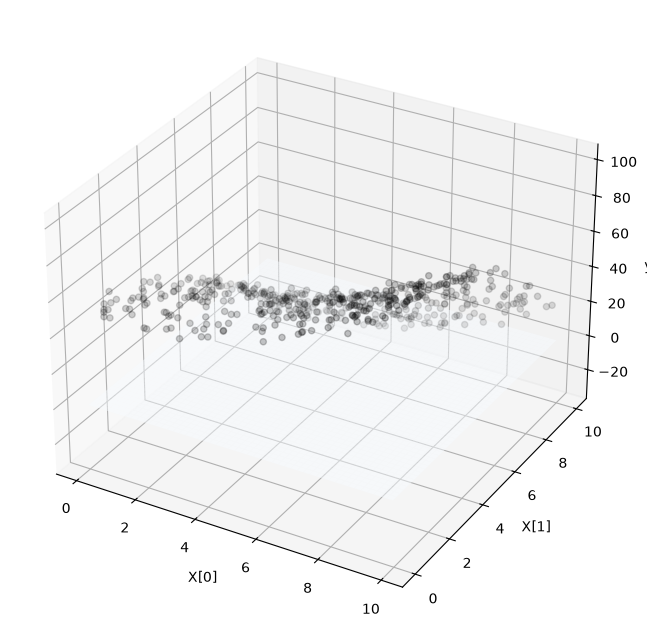

In [29]:
#plot
%matplotlib inline

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

#original data
ax.scatter(X[:, 0], X[:, 1], y, color='black', alpha=0.5)

#gaussian process fit
ax.plot_surface(X1, X2, y_pred4, cmap='Blues', alpha=0.5)

ax.set_xlabel('X[0]')
ax.set_ylabel('X[1]')
ax.set_zlabel('y')

plt.show()

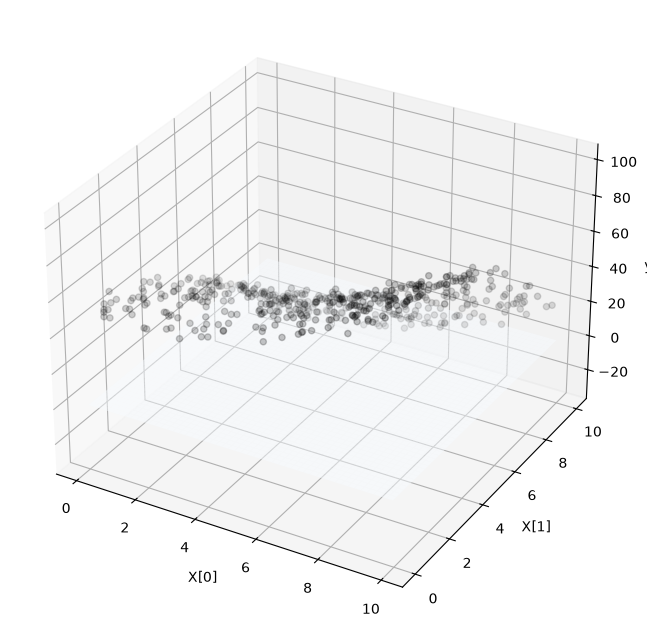

In [38]:
#plot
%matplotlib inline

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:, 0], X[:, 1], y, color='black', alpha=0.5)

#gaussian process fit
ax.plot_surface(X1, X2, y_pred_err, cmap='Blues', alpha=0.5)

ax.set_xlabel('X[0]')
ax.set_ylabel('X[1]')
ax.set_zlabel('y')

plt.show()

In [39]:
#part 6
#import
from astroML.linear_model import PolynomialRegression

In [40]:
poly = PolynomialRegression(degree=4)
poly.fit(X, y)

print("regression coefficients:")
print(poly.coef_)

regression coefficients:
[ 5.00363666e+01  3.26437755e-01  7.04566290e-02  3.76478281e-01
 -2.37398556e-02 -8.70986046e-01  1.19122182e-02  2.54637597e-02
 -1.32002013e-02  2.02705370e-02 -4.53796076e-04 -5.21142180e-04
 -2.06194460e-03  1.68744189e-03 -1.52054198e-03]


In [41]:
#predict
y_pred_poly = poly.predict(Xgrid_new)
y_pred_poly = y_pred_poly.reshape(X1.shape)

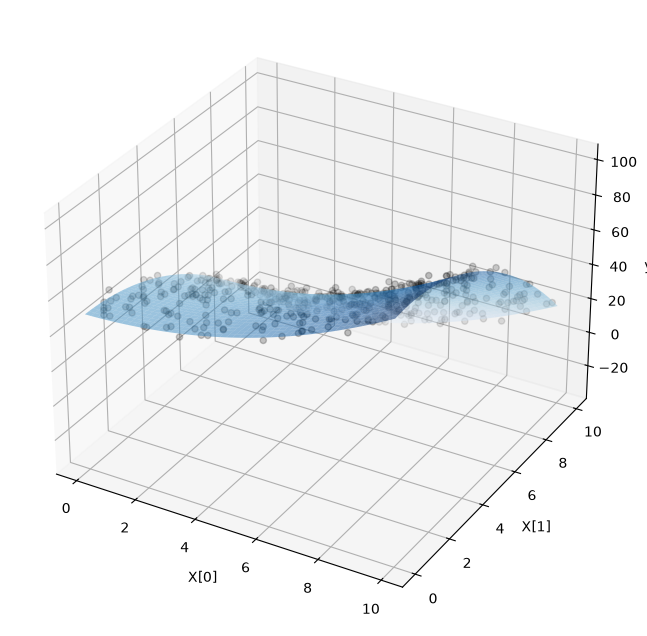

In [42]:
#plot
%matplotlib inline

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:, 0], X[:, 1], y,
           color='black', alpha=0.5)

#polynomial fit
ax.plot_surface(X1, X2, y_pred_poly,
                cmap='Blues', alpha=0.5)

ax.set_xlabel('X[0]')
ax.set_ylabel('X[1]')
ax.set_zlabel('y')

plt.show()

In [44]:
#linear regression produces a flat plane whereas the polynomial regression
#produces a curved surface

In [45]:
#part 7
#import
from sklearn.model_selection import train_test_split

In [46]:
#first split
X_train, X_test, y_train, y_test, yerr_train, yerr_test = train_test_split(
    X, y, yerr, test_size=0.2, random_state=42
)

#second split
X_train, X_cv, y_train, y_cv, yerr_train, yerr_cv = train_test_split(
    X_train, y_train, yerr_train, test_size=0.2, random_state=42
)

In [53]:
#fit polynomial models for different degrees ranging from 1 to 10
degrees = np.arange(1, 11)

train_rms = []
cv_rms = []
train_bic = []
cv_bic = []

for degree in degrees:

    #fit polynomial model
    poly = PolynomialRegression(degree=degree)
    poly.fit(X_train, y_train, yerr_train)

    #predict training and cross-validation data
    y_train_pred = poly.predict(X_train)
    y_cv_pred = poly.predict(X_cv)

    #calculate residuals
    train_residuals = y_train - y_train_pred
    cv_residuals = y_cv - y_cv_pred

    #calculate RMS errors
    rms_train = np.sqrt(np.mean(train_residuals**2))
    rms_cv = np.sqrt(np.mean(cv_residuals**2))

    train_rms.append(rms_train)
    cv_rms.append(rms_cv)

    #calculate BIC
    k = (degree + 1) * (degree + 2) / 2

    rss_train = np.sum(train_residuals**2)
    rss_cv = np.sum(cv_residuals**2)

    bic_train = len(y_train) * np.log(rss_train / len(y_train)) + k * np.log(len(y_train))
    bic_cv = len(y_cv) * np.log(rss_cv / len(y_cv)) + k * np.log(len(y_cv))

    train_bic.append(bic_train)
    cv_bic.append(bic_cv)

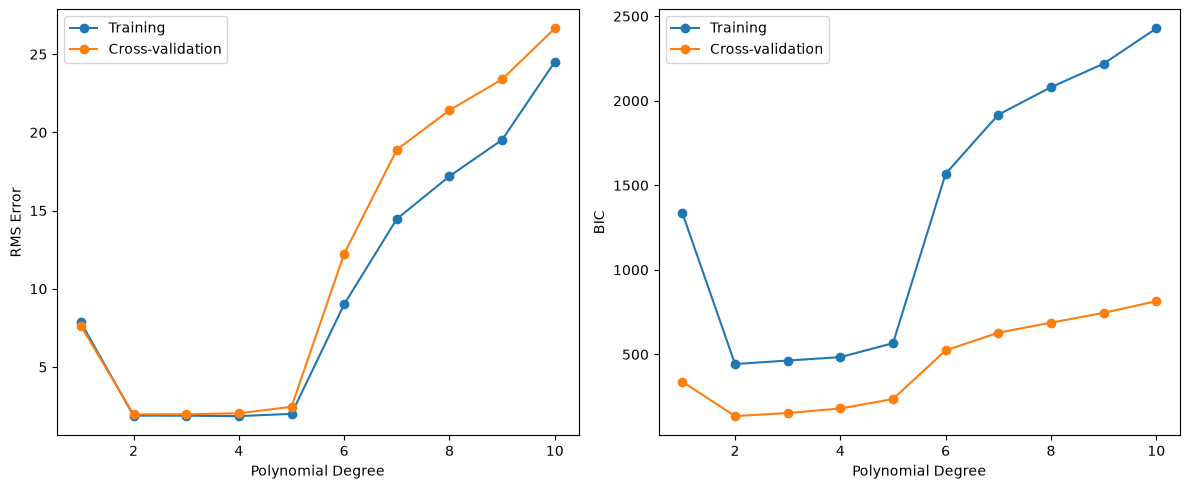

In [54]:
#plot
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

#RMS errors
ax[0].plot(degrees, train_rms, 'o-', label='Training')
ax[0].plot(degrees, cv_rms, 'o-', label='Cross-validation')
ax[0].set_xlabel('Polynomial Degree')
ax[0].set_ylabel('RMS Error')
ax[0].legend()

#BIC values
ax[1].plot(degrees, train_bic, 'o-', label='Training')
ax[1].plot(degrees, cv_bic, 'o-', label='Cross-validation')
ax[1].set_xlabel('Polynomial Degree')
ax[1].set_ylabel('BIC')
ax[1].legend()

plt.tight_layout()
plt.show()

In [55]:
#choose and test optimal degree
best_degree = degrees[np.argmin(cv_bic)]
print("optimal polynomial degree:", best_degree)

optimal polynomial degree: 2


In [56]:
#fit the degree
best_poly = PolynomialRegression(degree=best_degree)
best_poly.fit(
    np.concatenate((X_train, X_cv)),
    np.concatenate((y_train, y_cv)),
    np.concatenate((yerr_train, yerr_cv))
)

,degree,np.int64(2)
,interaction_only,False
,fit_intercept,True
,regularization,'none'
,kwds,None
Name,Type,Value
clf_,LinearRegression,LinearRegress...tercept=False)
coef_,"ndarray[float64](6,)","[49.87, 0.09, 0.16, 0.49,-0. ,-0.82]"


In [57]:
#predict test set and calculate rms error
y_test_pred = best_poly.predict(X_test)
test_rms = np.sqrt(np.mean((y_test - y_test_pred)**2))
print("testing RMS error:", test_rms)

testing RMS error: 1.9492137379315877


## Problem 2


1. Use the following code snippet to read in SDSS galaxy color data.
<!--```
from astroML.datasets import fetch_sdss_galaxy_colors
data = fetch_sdss_galaxy_colors()
```-->

`data = np.load('../hw_data/hw7_data_2.npy')`

This is a structured numpy array. Find and print all of the column names. Using the data, create arrays of $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create arrays of redshift and the spectral class. How many regular galaxies and how many quasars are in this sample?


2. Make a scatter plot of $(u-g)$ versus $(g-r)$, color coding by galaxy or quasar class. The plot should include appropriate axis labels and a legend. Set `xlim` between -0.5 and 2.5, and `ylim` between -0.5 and 1.5.


3. Stack all colors and the redshift into a data matrix, $X$. Create a target label array that has $0$ for a regular galaxy and $1$ for a quasar. Perform a train-test split, taking $20\%$ of the data for testing.


4. Create a compact `for` loop that iterates over the fitting of a Gaussian Naive Bayes classification algorithm to successively more features of the data. Within the loop, compute and plot an ROC curve. The end result should be a plot showing ROC curves for GNB classification with more and more features of the data, with appropriate axis labels and a legend. Use `xlim` between 0 and 0.01. Which feature seems to make the classification trivially easy? *Note: `predict_proba` returns an array with as many columns as classes. You've labeled quasars as $1$, so for the ROC curve you must make sure to access the relevant quasar probability-- you can find this by accessing the **classes_** attribute of the estimator.*


5. Repeat (4) for Quadratic Discriminant Analysis. 


6. Let's try classification with GMM Bayes. Restrict the training and testing to be just on the $4$ colors. Iterate now over number of components in the GMM Bayes fit up to $10$, plotting ROC curves for all, and find the number of components that gives the best performance.


7. Repeat (6) for $K$-nearest neighbor classification, looping over number of neighbors between 5 and 100 in steps of 10. Find the number that gives the best performance. 


8. Repeat (6) for Decision Tree classification, looping over the maximum tree depth between 1 and 10. Find the number that gives the best performance. 


9. Finally, plot the ROC curves for GNB, QDA, and the best-performing GMMBayes, KNN, and DT classification algorithms, all using just the 4 colors. What is the overall best-performing classifier? 


10. Make a 2-panel plot, showing in the left panel the color-coded training data in $(u-g)$ versus $(g-r)$ (similar to item 2 above), and in the right panel the same features of the testing data color coded by their predicted class from the tuned best-performing classifier. 

In [61]:
#part 1
#load data
data = np.load('hw_data/hw7_data_2.npy')
print(data.dtype.names)

('u', 'g', 'r', 'i', 'z', 'specClass', 'redshift', 'redshift_err')


In [62]:
#color arrays
u_g = data['u'] - data['g']
g_r = data['g'] - data['r']
r_i = data['r'] - data['i']
i_z = data['i'] - data['z']

In [63]:
#redshift and spectral class
redshift = data['redshift']
spec_class = data['specClass']

In [64]:
#count
print(np.unique(spec_class, return_counts=True))

(array(['GALAXY', 'QSO'], dtype='<U6'), array([42808,  7192]))


In [65]:
n_galaxies = np.sum(spec_class == 'GALAXY')
n_quasars = np.sum(spec_class == 'QSO')

print("regular galaxies:", n_galaxies)
print("quasars:", n_quasars)

regular galaxies: 42808
quasars: 7192


In [66]:
#part 2
#spectral classes
galaxies = spec_class == 'GALAXY'
quasars = spec_class == 'QSO'

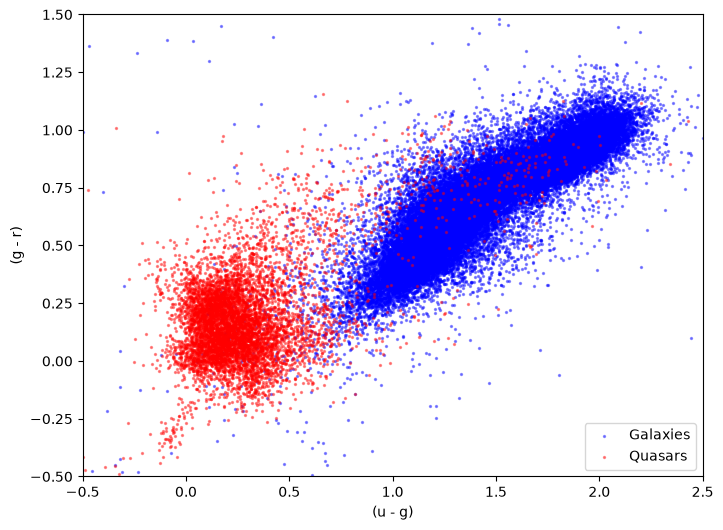

In [68]:
#scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(u_g[galaxies], g_r[galaxies],
            color='blue', s=2, alpha=0.4, label='Galaxies')

plt.scatter(u_g[quasars], g_r[quasars],
            color='red', s=2, alpha=0.4, label='Quasars')

#axis labels and limits
plt.xlabel('(u - g)')
plt.ylabel('(g - r)')

plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 1.5)

plt.legend()
plt.show()

In [69]:
#part 3
#stack
X = np.column_stack((u_g, g_r, r_i, i_z, redshift))

In [70]:
#target label array
y = np.zeros(len(spec_class))
y[spec_class == 'QSO'] = 1

In [72]:
#train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [73]:
#results
print("X shape:", X.shape)
print("training set:", X_train.shape)
print("testing set:", X_test.shape)
print("training labels:", np.unique(y_train, return_counts=True))
print("testing labels:", np.unique(y_test, return_counts=True))

X shape: (50000, 5)
training set: (40000, 5)
testing set: (10000, 5)
training labels: (array([0., 1.]), array([34264,  5736]))
testing labels: (array([0., 1.]), array([8544, 1456]))


In [74]:
#part 4
#imports
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve

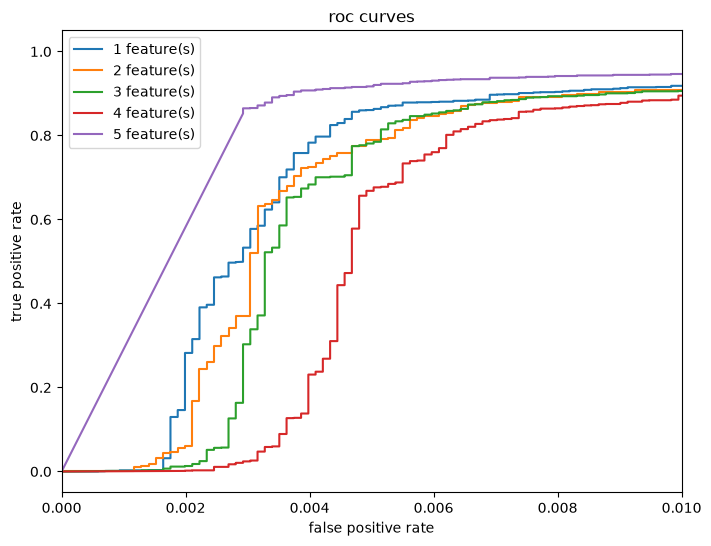

In [77]:
#plot
plt.figure(figsize=(8, 6))

feature_names = ['u-g', 'g-r', 'r-i', 'i-z', 'redshift']

#fit models and calculate roc curves
for i in range(1, 6):

    #fit using the first i features
    gnb = GaussianNB()
    gnb.fit(X_train[:, :i], y_train)

    #find the column corresponding to quasars 
    qso_index = np.where(gnb.classes_ == 1)[0][0]

    #predict quasar probabilities
    y_score = gnb.predict_proba(X_test[:, :i])[:, qso_index]

    #calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    #plot ROC curve
    plt.plot(fpr, tpr, label=f'{i} feature(s)')

plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.xlim(0, 0.01)
plt.legend()
plt.title('roc curves')
plt.show()

In [79]:
#based on the plot, the redshift feature seems to make 
#classification trivially easy

In [80]:
#part 5
#import
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

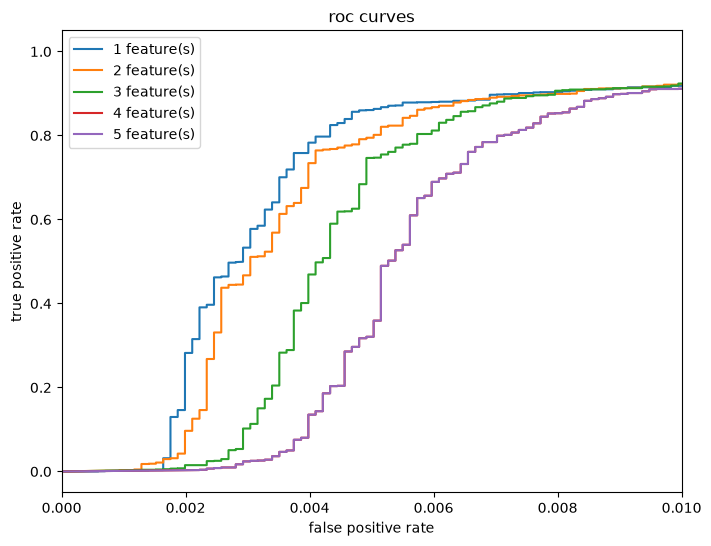

In [88]:
#plot
plt.figure(figsize=(8, 6))

feature_names = ['u-g', 'g-r', 'r-i', 'i-z', 'redshift']

#fit models and calculate roc curves
for i in range(1, 6):

    #fit using the first i features
    qda = QuadraticDiscriminantAnalysis()
    qda.fit(X_train[:, :i], y_train)

    #find the column corresponding to quasars 
    qso_index = np.where(qda.classes_ == 1)[0][0]

    #predict quasar probabilities
    y_score = qda.predict_proba(X_test[:, :i])[:, qso_index]

    #calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    #plot ROC curve
    plt.plot(fpr, tpr, label=f'{i} feature(s)')

plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.xlim(0, 0.01)
plt.legend()
plt.title('roc curves')
plt.show()

In [89]:
#redshift still makes the classification better

In [90]:
#part 6
#exclude redshift
# Use only the four color features (exclude redshift)
X_colors = X[:, :4]

In [91]:
#split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_colors, y, test_size=0.2, random_state=42
)

In [96]:
#imports
from sklearn.mixture import GaussianMixture
from scipy.special import logsumexp
from sklearn.metrics import roc_auc_score

In [97]:
#area under curve
aucs = []

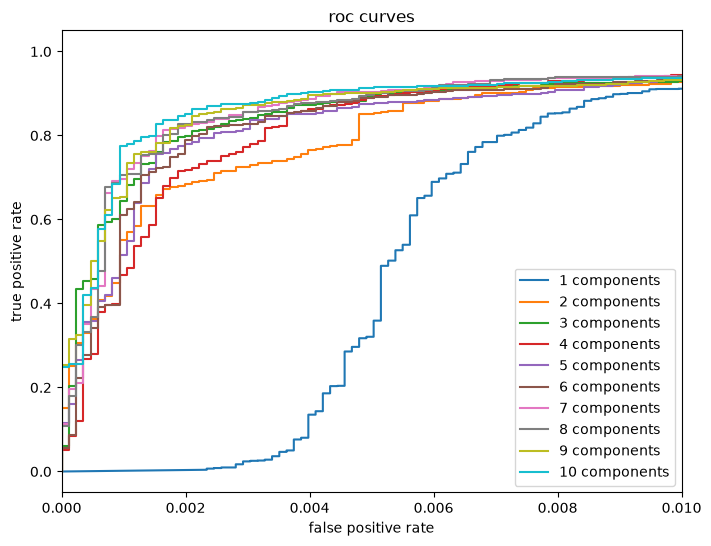

In [98]:
#plot
plt.figure(figsize=(8, 6))

for n in range(1, 11):

    #Fit a GMM to each class
    gmm_galaxy = GaussianMixture(n_components=n, random_state=42)
    gmm_qso = GaussianMixture(n_components=n, random_state=42)

    gmm_galaxy.fit(X_train[y_train == 0])
    gmm_qso.fit(X_train[y_train == 1])

    #Calculate likelihoods for the test data
    p_galaxy = gmm_galaxy.score_samples(X_test)
    p_qso = gmm_qso.score_samples(X_test)

    #calculate log-likelihoods
    log_p_galaxy = gmm_galaxy.score_samples(X_test)
    log_p_qso = gmm_qso.score_samples(X_test)

    #include class priors
    log_galaxy = log_p_galaxy + np.log(prior_galaxy)
    log_qso = log_p_qso + np.log(prior_qso)

    #calculate quasar probabilities 
    qso_probability = np.exp(
        log_qso - np.logaddexp(log_qso, log_galaxy)
    )

    #area under curves
    aucs.append(roc_auc_score(y_test, qso_probability))
    
    #Calculate and plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, qso_probability)

    plt.plot(fpr, tpr, label=f'{n} components')

plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.xlim(0, 0.01)
plt.legend()
plt.title('roc curves')
plt.show()

In [99]:
#find best number of components
best_n = np.argmax(aucs) + 1
print("best number of components:", best_n)
print("best AUC:", aucs[best_n - 1])

best number of components: 8
best AUC: 0.9915187735368562


In [102]:
#part 7
#import
from sklearn.neighbors import KNeighborsClassifier

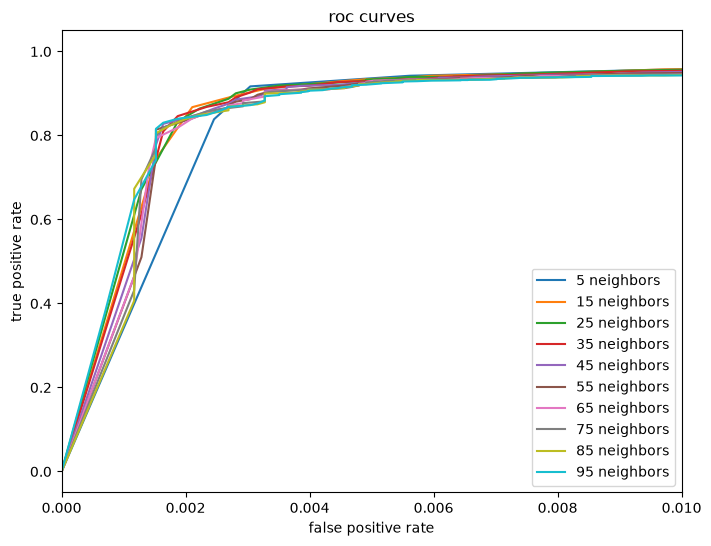

In [103]:
#plot
plt.figure(figsize=(8, 6))

neighbors = range(5, 100, 10)
aucs = []

for k in neighbors:

    #fit KNN classifier
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    #predict probabilities of being a quasar
    y_score = knn.predict_proba(X_test)[:, 1]

    #calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    #area under curves
    aucs.append(roc_auc_score(y_test, y_score))

    #plot ROC curve
    plt.plot(fpr, tpr, label=f'{k} neighbors')

plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.xlim(0, 0.01)
plt.legend()
plt.title('roc curves')
plt.show()

In [105]:
best_k = list(neighbors)[np.argmax(aucs)]

print("best number of neighbors:", best_k)
print("best AUC:", max(aucs))

best number of neighbors: 95
best AUC: 0.9922689706419516


In [106]:
#part 8
#import
from sklearn.tree import DecisionTreeClassifier

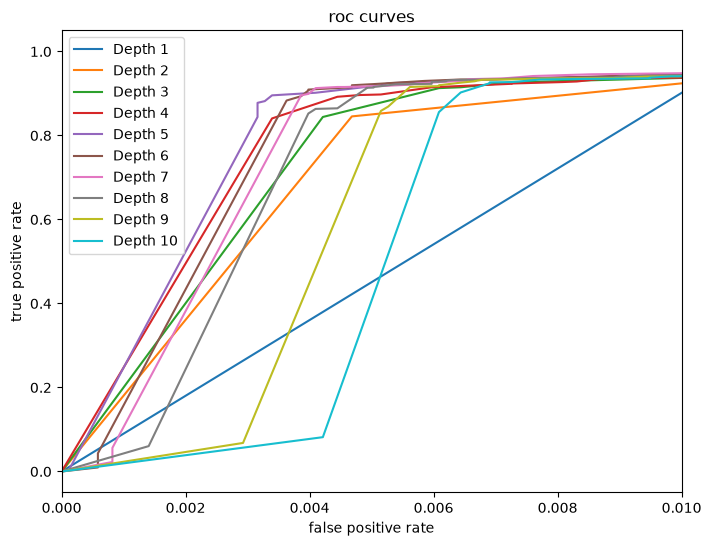

In [107]:
#plot
plt.figure(figsize=(8, 6))

depths = range(1, 11)
aucs = []

for depth in depths:

    #fit Decision Tree classifier
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    #predict probabilities of being a quasar
    y_score = tree.predict_proba(X_test)[:, 1]

    #calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_score)

    #area under curves
    aucs.append(roc_auc_score(y_test, y_score))

    #plot ROC curve
    plt.plot(fpr, tpr, label=f'Depth {depth}')

plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.xlim(0, 0.01)
plt.legend()
plt.title('roc curves')
plt.show()

In [108]:
best_depth = list(depths)[np.argmax(aucs)]
print("best maximum depth:", best_depth)
print("best AUC:", max(aucs))

best maximum depth: 6
best AUC: 0.9803963227198831


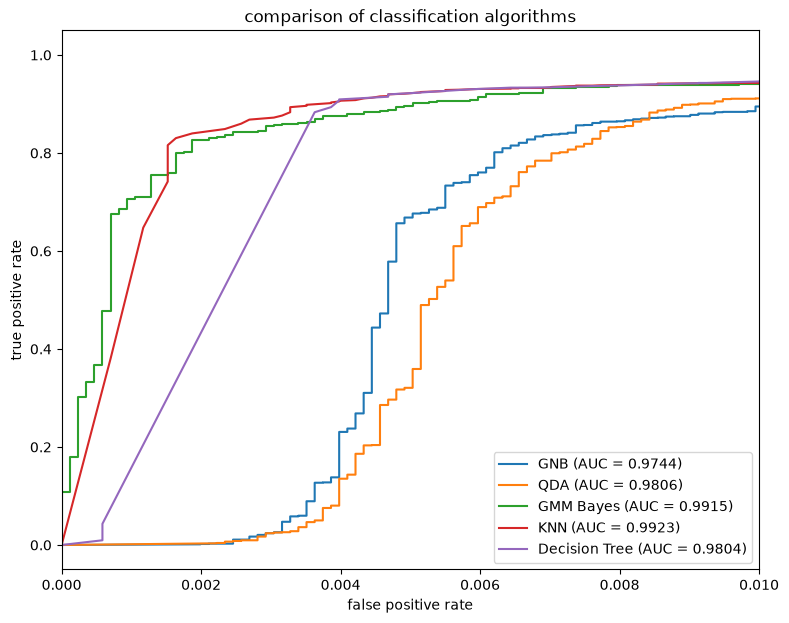

In [110]:
#part 9
#plotting all the roc curves
plt.figure(figsize=(9, 7))

aucs = {}

#Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_score = gnb.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_score)
aucs['GNB'] = roc_auc_score(y_test, y_score)
plt.plot(fpr, tpr, label=f"GNB (AUC = {aucs['GNB']:.4f})")


#Quadratic Discriminant Analysis
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train, y_train)
y_score = qda.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_score)
aucs['QDA'] = roc_auc_score(y_test, y_score)
plt.plot(fpr, tpr, label=f"QDA (AUC = {aucs['QDA']:.4f})")


#best-performing GMM Bayes
best_gmm_galaxy = GaussianMixture(n_components=best_n, random_state=42)
best_gmm_qso = GaussianMixture(n_components=best_n, random_state=42)

best_gmm_galaxy.fit(X_train[y_train == 0])
best_gmm_qso.fit(X_train[y_train == 1])

log_galaxy = best_gmm_galaxy.score_samples(X_test) + np.log(np.mean(y_train == 0))
log_qso = best_gmm_qso.score_samples(X_test) + np.log(np.mean(y_train == 1))

y_score = np.exp(log_qso - np.logaddexp(log_qso, log_galaxy))

fpr, tpr, _ = roc_curve(y_test, y_score)
aucs['GMM Bayes'] = roc_auc_score(y_test, y_score)
plt.plot(fpr, tpr, label=f"GMM Bayes (AUC = {aucs['GMM Bayes']:.4f})")


#best-performing KNN
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)
y_score = best_knn.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_score)
aucs['KNN'] = roc_auc_score(y_test, y_score)
plt.plot(fpr, tpr, label=f"KNN (AUC = {aucs['KNN']:.4f})")


#best-performing Decision Tree
best_tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_tree.fit(X_train, y_train)
y_score = best_tree.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_score)
aucs['Decision Tree'] = roc_auc_score(y_test, y_score)
plt.plot(fpr, tpr, label=f"Decision Tree (AUC = {aucs['Decision Tree']:.4f})")


plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.xlim(0, 0.01)
plt.legend()
plt.title('comparison of classification algorithms')
plt.show()

In [112]:
best_classifier = max(aucs, key=aucs.get)
print("overall best classifier:", best_classifier)
print("best AUC:", aucs[best_classifier])

overall best classifier: KNN
best AUC: 0.9922689706419516


In [116]:
#part 10
#get predictions from the best-performing classifier
y_pred = best_knn.predict(X_test)

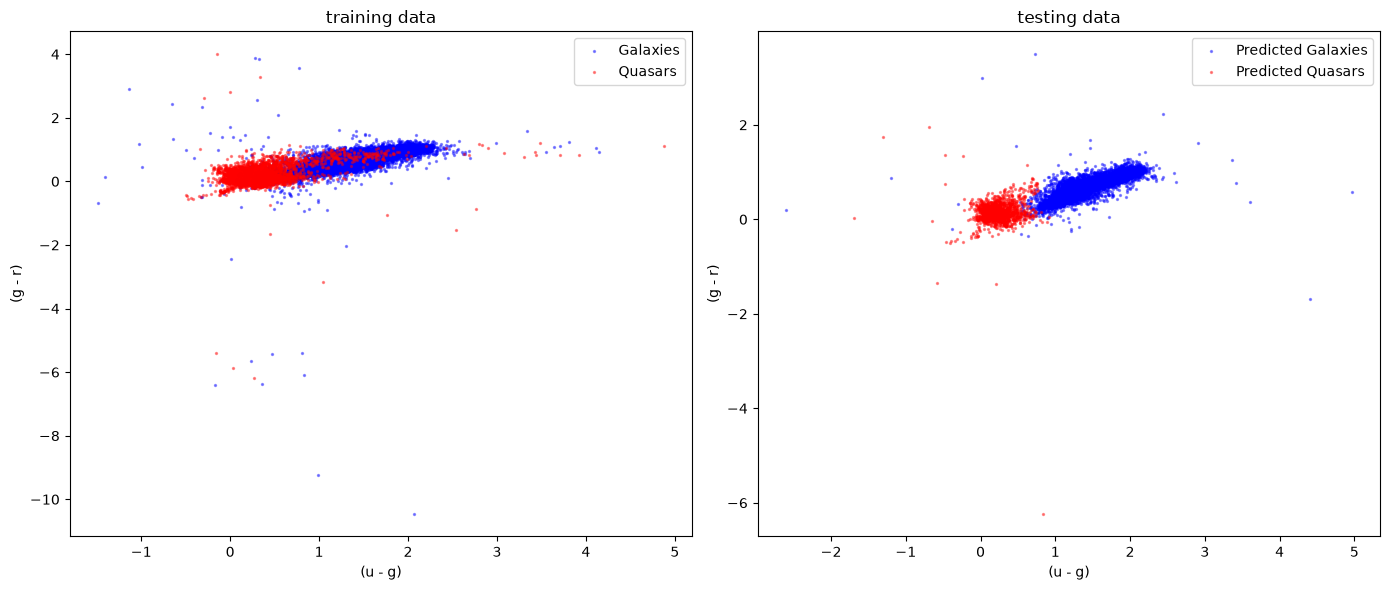

In [117]:
#plot
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

#left panel
ax[0].scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
              color='blue', s=2, alpha=0.4, label='Galaxies')

ax[0].scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
              color='red', s=2, alpha=0.4, label='Quasars')

ax[0].set_xlabel('(u - g)')
ax[0].set_ylabel('(g - r)')
ax[0].set_title('training data')
ax[0].legend()


#right panel
ax[1].scatter(X_test[y_pred == 0, 0], X_test[y_pred == 0, 1],
              color='blue', s=2, alpha=0.4, label='Predicted Galaxies')

ax[1].scatter(X_test[y_pred == 1, 0], X_test[y_pred == 1, 1],
              color='red', s=2, alpha=0.4, label='Predicted Quasars')

ax[1].set_xlabel('(u - g)')
ax[1].set_ylabel('(g - r)')
ax[1].set_title('testing data')
ax[1].legend()

plt.tight_layout()
plt.show()